In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('heart.csv')

# EDA

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.shape

(918, 12)

In [5]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [7]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [8]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [9]:
df['HeartDisease'].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

<Axes: xlabel='HeartDisease'>

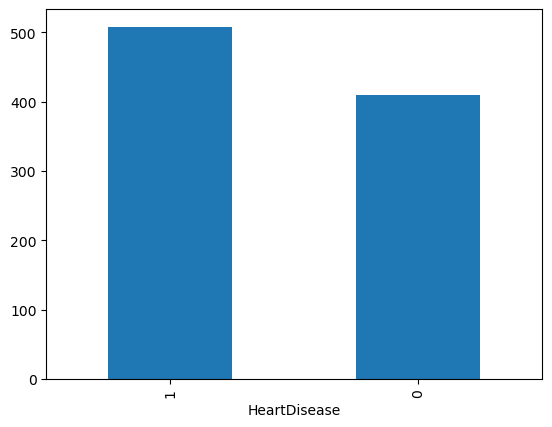

In [10]:
df['HeartDisease'].value_counts().plot(kind='bar')

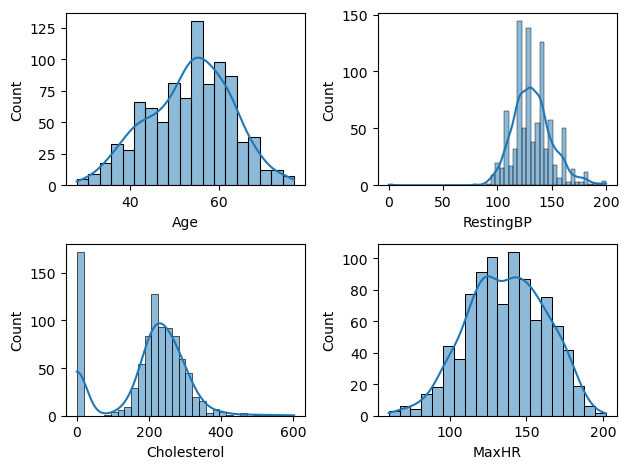

In [11]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)


plt.tight_layout()

In [12]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
230      9
      ... 
392      1
316      1
153      1
466      1
131      1
Name: count, Length: 222, dtype: int64

In [13]:
df['RestingBP'].value_counts()

RestingBP
120    132
130    118
140    107
110     58
150     55
      ... 
185      1
98       1
92       1
113      1
164      1
Name: count, Length: 67, dtype: int64

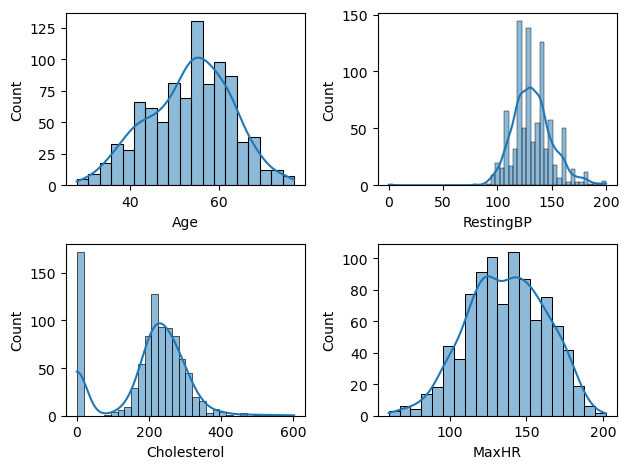

In [14]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)


plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

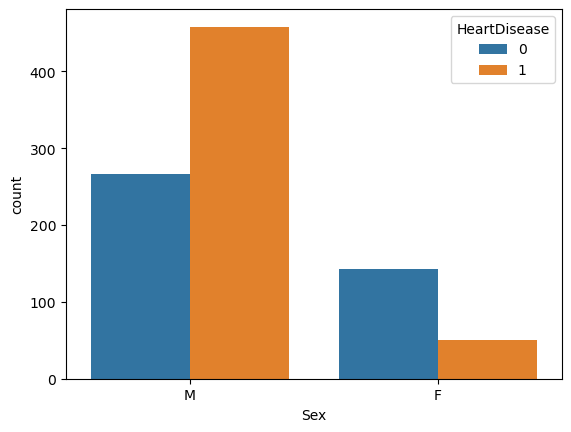

In [15]:
sns.countplot(x= df['Sex'], hue = df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

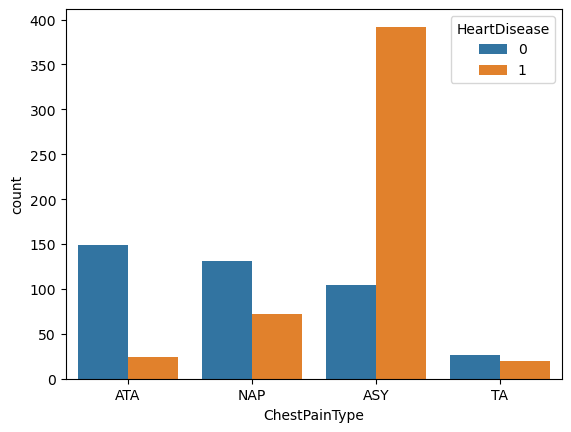

In [16]:
sns.countplot(x= df['ChestPainType'], hue = df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

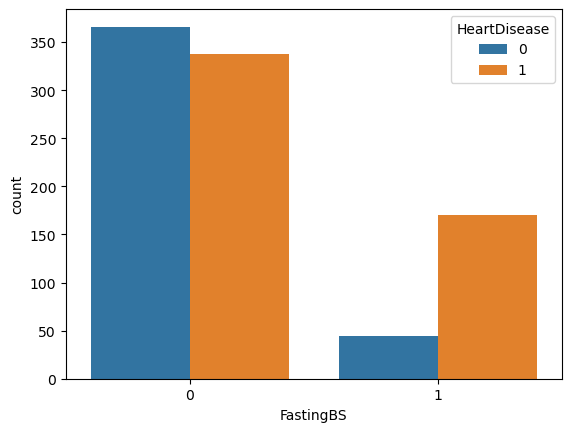

In [17]:
sns.countplot(x= df['FastingBS'], hue = df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

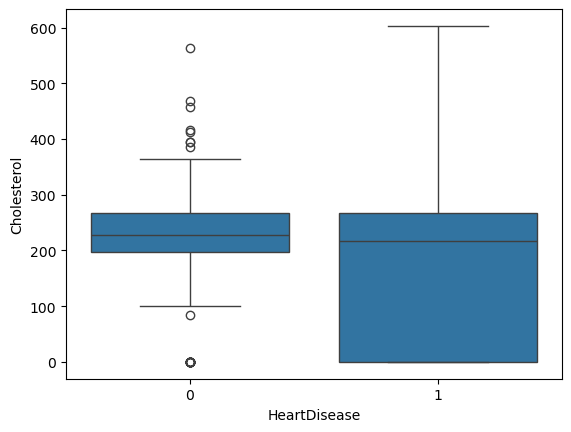

In [18]:
sns.boxplot(x = df['HeartDisease'],y= df['Cholesterol'])

<Axes: xlabel='HeartDisease', ylabel='Age'>

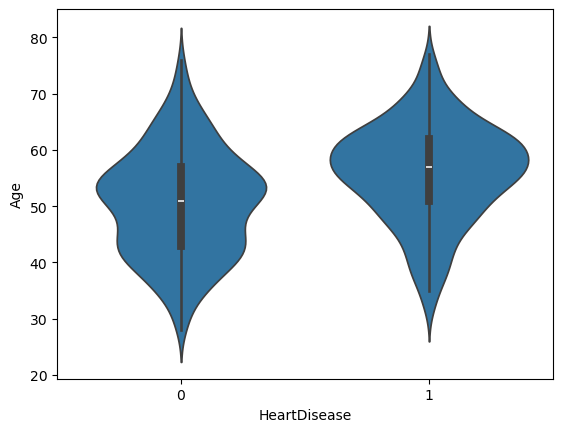

In [19]:
sns.violinplot(x = df['HeartDisease'],y= df['Age'])

<Axes: >

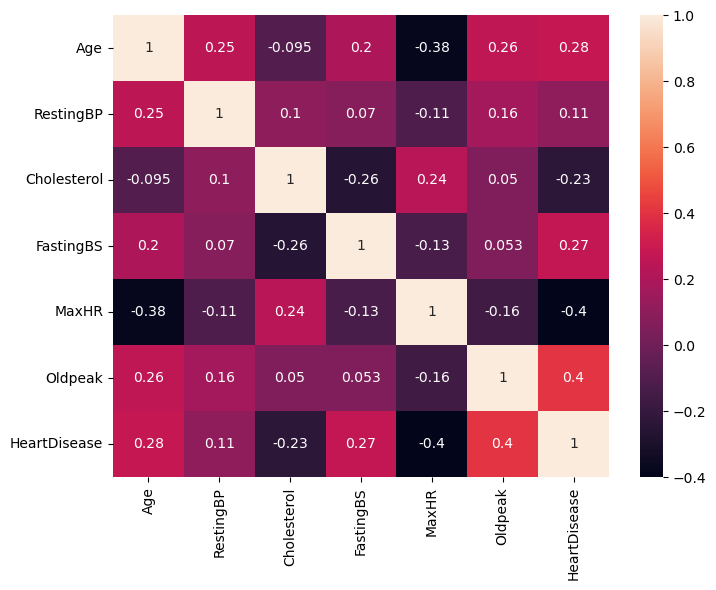

In [20]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

# Data Preprocessing and Cleaning

In [21]:
df_encode = pd.get_dummies(df,drop_first=True)

In [22]:
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1.2,1,True,False,False,True,True,False,False,True,False
914,68,144,193,1,141,3.4,1,True,False,False,False,True,False,False,True,False
915,57,130,131,0,115,1.2,1,True,False,False,False,True,False,True,True,False
916,57,130,236,0,174,0.0,1,False,True,False,False,False,False,False,True,False


# Feature Engineering and Extraction

In [23]:
#Pearson Correlation Calculation

correlation_with_heart_disease = (
    df_encode.corr(method="pearson")["HeartDisease"]
    .drop("HeartDisease")
    .sort_values(ascending=False)
    .reset_index()
)

correlation_with_heart_disease.columns = ["Feature", "Pearson_Correlation"]

In [24]:
correlation_with_heart_disease

,Feature,Pearson_Correlation
0,ST_Slope_Flat,0.554134
1,ExerciseAngina_Y,0.494282
2,Oldpeak,0.403951
3,Sex_M,0.305445
4,Age,0.282039
5,FastingBS,0.267291
6,RestingBP,0.107589
7,RestingECG_ST,0.102527
8,ChestPainType_TA,-0.054790
9,RestingECG_Normal,-0.091580


In [25]:
#Chi Square Test

from scipy.stats import chi2_contingency
import pandas as pd

cat_features = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope",
    "FastingBS"
]

alpha = 0.05

chi2_results = {}

for col in cat_features:
    
    table = pd.crosstab(
        df[col],
        df["HeartDisease"]
    )
    
    chi2_stat, p_value, dof, expected = chi2_contingency(table)
    
    if p_value < alpha:
        decision = "Significant"
    else:
        decision = "Not Significant"
    
    chi2_results[col] = {
        "Chi2_Statistic": chi2_stat,
        "P_Value": p_value,
        "Decision": decision
    }

chi2_df = pd.DataFrame(chi2_results).T

chi2_df = chi2_df.sort_values(
    by="P_Value"
)

chi2_df

,Chi2_Statistic,P_Value,Decision
ST_Slope,355.918443,0.0,Significant
ChestPainType,268.067239,0.0,Significant
ExerciseAngina,222.259383,0.0,Significant
Sex,84.145101,0.0,Significant
FastingBS,64.320679,0.0,Significant
RestingECG,10.931469,0.004229,Significant


In [26]:
final_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak",
    "FastingBS",
    "Sex_M",
    "ChestPainType_ATA",
    "ChestPainType_NAP",
    "ChestPainType_TA",
    "RestingECG_Normal",
    "RestingECG_ST",
    "ExerciseAngina_Y",
    "ST_Slope_Flat",
    "ST_Slope_Up"
]

In [27]:
df_final = df_encode[final_features + ["HeartDisease"]].copy()

df_final.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,FastingBS,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,HeartDisease
0,40,140,289,172,0.0,0,True,True,False,False,True,False,False,False,True,0
1,49,160,180,156,1.0,0,False,False,True,False,True,False,False,True,False,1
2,37,130,283,98,0.0,0,True,True,False,False,False,True,False,False,True,0
3,48,138,214,108,1.5,0,False,False,False,False,True,False,True,True,False,1
4,54,150,195,122,0.0,0,True,False,True,False,True,False,False,False,True,0


In [28]:
df_final

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,FastingBS,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,HeartDisease
0,40,140,289,172,0.0,0,True,True,False,False,True,False,False,False,True,0
1,49,160,180,156,1.0,0,False,False,True,False,True,False,False,True,False,1
2,37,130,283,98,0.0,0,True,True,False,False,False,True,False,False,True,0
3,48,138,214,108,1.5,0,False,False,False,False,True,False,True,True,False,1
4,54,150,195,122,0.0,0,True,False,True,False,True,False,False,False,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,132,1.2,0,True,False,False,True,True,False,False,True,False,1
914,68,144,193,141,3.4,1,True,False,False,False,True,False,False,True,False,1
915,57,130,131,115,1.2,0,True,False,False,False,True,False,True,True,False,1
916,57,130,236,174,0.0,0,False,True,False,False,False,False,False,True,False,1


In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score

In [30]:
X = df_final.drop('HeartDisease',axis=1)
y= df_final['HeartDisease']

In [31]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [32]:
X_train = X_train.copy()
X_test = X_test.copy()

for col in ['Cholesterol', 'RestingBP']:
    mean_value = X_train.loc[X_train[col] != 0, col].mean()

    X_train[col] = X_train[col].replace(0, mean_value)
    X_test[col] = X_test[col].replace(0, mean_value)

In [33]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes":GaussianNB(),
    "Decision tree":DecisionTreeClassifier(),
    "SVM":SVC()
}

In [35]:
result = []

In [36]:
for name,model in models.items():
    model.fit(X_train_scaled,y_train)
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    result.append({
        'model':name,
        'accuracy':round(accuracy,4),
        'f1 score':round(f1,4)
    })

In [37]:
result

[{'model': 'Logistic Regression', 'accuracy': 0.8641, 'f1 score': 0.8792},
 {'model': 'KNN', 'accuracy': 0.8533, 'f1 score': 0.8708},
 {'model': 'Naive Bayes', 'accuracy': 0.8478, 'f1 score': 0.8614},
 {'model': 'Decision tree', 'accuracy': 0.7989, 'f1 score': 0.8141},
 {'model': 'SVM', 'accuracy': 0.8587, 'f1 score': 0.8762}]

In [38]:
import joblib

joblib.dump(models['Logistic Regression'], 'LogisticRegression_heart.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(X.columns.tolist(), 'columns.pkl')
joblib.dump({
    'Cholesterol': X_train['Cholesterol'].mean(),
    'RestingBP': X_train['RestingBP'].mean()
}, 'fill_values.pkl')

print("All 4 PKL files saved successfully!")

All 4 PKL files saved successfully!
